In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter

# Read the classes file
with open('/content/classes.txt', 'r') as f:
    lines = [line.strip() for line in f.readlines() if line.strip()]

# Perform EDA
total_lines = len(lines)
unique_classes = set(lines)
class_counts = Counter(lines)

print(f"Total items: {total_lines}")
print(f"Unique classes count: {len(unique_classes)}")
print("\nClass Distributions:")
for cls, count in class_counts.most_common():
    print(f" - {cls}: {count} ({count/total_lines*100:.2f}%)")

Total items: 6
Unique classes count: 6

Class Distributions:
 - Coca Cola: 1 (16.67%)
 - Sprite: 1 (16.67%)
 - Pepsi: 1 (16.67%)
 - Mountain Dew: 1 (16.67%)
 - 7UP: 1 (16.67%)
 - Fanta: 1 (16.67%)


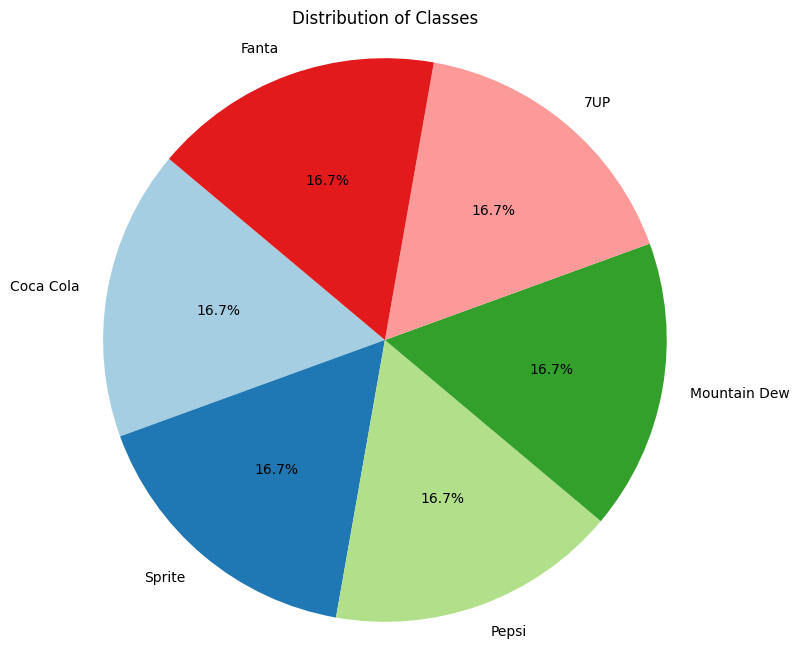

In [2]:
# Generate a pie chart of the classes
if class_counts:
    labels, values = zip(*class_counts.most_common())

    plt.figure(figsize=(8, 8))
    plt.pie(values, labels=labels, autopct='%1.1f%%', startangle=140, colors=plt.cm.Paired.colors)
    plt.title('Distribution of Classes')
    plt.axis('equal')
    plt.show()
else:
    print("No data available to plot.")

### Machine Learning with a Decision Tree
Since we only have the class text names (targets), we need some features to train a model. We will convert the text strings to numerical features using `TfidfVectorizer` (treating the labels themselves as text input for demonstration), perform an 80/20 train/test split, and train a `DecisionTreeClassifier`.

In [3]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.tree import DecisionTreeClassifier
from sklearn import metrics

# Prepare dummy features based on the labels for demonstration purposes
# In a real scenario, you would have descriptive feature columns corresponding to these classes
X = lines
y = lines

# Vectorize the text data to create numerical features
vectorizer = TfidfVectorizer()
X_vectorized = vectorizer.fit_transform(X)

# Split the dataset into 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X_vectorized, y, test_size=0.20, random_state=42
)

print(f"Training set size: {X_train.shape[0]} samples")
print(f"Testing set size: {X_test.shape[0]} samples")

Training set size: 4 samples
Testing set size: 2 samples


In [4]:
# Initialize and train the Decision Tree Classifier
clf = DecisionTreeClassifier(random_state=42)
clf.fit(X_train, y_train)

# Predict the response for the test dataset
y_pred = clf.predict(X_test)

# Model Accuracy
accuracy = metrics.accuracy_score(y_test, y_pred)
print(f"Decision Tree Model Accuracy: {accuracy * 100:.2f}%")

# Display classification report
print("\nClassification Report:")
print(metrics.classification_report(y_test, y_pred, zero_division=0))

Decision Tree Model Accuracy: 0.00%

Classification Report:
              precision    recall  f1-score   support

   Coca Cola       0.00      0.00      0.00       1.0
       Pepsi       0.00      0.00      0.00       0.0
      Sprite       0.00      0.00      0.00       1.0

    accuracy                           0.00       2.0
   macro avg       0.00      0.00      0.00       2.0
weighted avg       0.00      0.00      0.00       2.0



### Predict 10 Random Drinks
Since our dataset contains only 6 samples, we will generate a synthetic set of 10 random drink descriptions/names to run through our trained vectorizer and Decision Tree model.

In [5]:
import random

# Synthetic list of 10 drink samples (some matched with training, some slightly varied)
synthetic_test_data = [
    ("Pepsi", "Pepsi"),
    ("Coca Cola", "Coca Cola"),
    ("Sprite Lemon", "Sprite"),
    ("Mountain Dew", "Mountain Dew"),
    ("7UP Lemon-Lime", "7UP"),
    ("Fanta Orange", "Fanta"),
    ("Diet Pepsi", "Pepsi"),
    ("Coca Cola Classic", "Coca Cola"),
    ("Fanta", "Fanta"),
    ("Mountain Dew Ice", "Mountain Dew")
]

# Extract names and true targets
test_names = [item[0] for item in synthetic_test_data]
true_labels = [item[1] for item in synthetic_test_data]

# Transform the test samples using our trained vectorizer
X_synthetic_vectorized = vectorizer.transform(test_names)

# Predict using our trained Decision Tree model
synthetic_preds = clf.predict(X_synthetic_vectorized)

# Create a DataFrame to present the comparison clearly
results_df = pd.DataFrame({
    "Input Drink Name": test_names,
    "Actual Label Group": true_labels,
    "Predicted Label": synthetic_preds
})

display(results_df)

,Input Drink Name,Actual Label Group,Predicted Label
0,Pepsi,Pepsi,Pepsi
1,Coca Cola,Coca Cola,Pepsi
2,Sprite Lemon,Sprite,Pepsi
3,Mountain Dew,Mountain Dew,Mountain Dew
4,7UP Lemon-Lime,7UP,7UP
5,Fanta Orange,Fanta,Fanta
6,Diet Pepsi,Pepsi,Pepsi
7,Coca Cola Classic,Coca Cola,Pepsi
8,Fanta,Fanta,Fanta
9,Mountain Dew Ice,Mountain Dew,Mountain Dew


In [6]:
from sklearn import metrics

# Generate classification report for the 10 random drink predictions
print("Classification Report for 10 Random Drink Predictions:")
print(metrics.classification_report(true_labels, synthetic_preds, zero_division=0))

Classification Report for 10 Random Drink Predictions:
              precision    recall  f1-score   support

         7UP       1.00      1.00      1.00         1
   Coca Cola       0.00      0.00      0.00         2
       Fanta       1.00      1.00      1.00         2
Mountain Dew       1.00      1.00      1.00         2
       Pepsi       0.40      1.00      0.57         2
      Sprite       0.00      0.00      0.00         1

    accuracy                           0.70        10
   macro avg       0.57      0.67      0.60        10
weighted avg       0.58      0.70      0.61        10



In [7]:
import joblib

# Save the trained model and the vectorizer to disk
joblib.dump(clf, 'decision_tree_model.joblib')
joblib.dump(vectorizer, 'tfidf_vectorizer.joblib')

print("Model and Vectorizer have been successfully saved to disk as 'decision_tree_model.joblib' and 'tfidf_vectorizer.joblib'!")

Model and Vectorizer have been successfully saved to disk as 'decision_tree_model.joblib' and 'tfidf_vectorizer.joblib'!
